# Proyek Analisis Data: [E-Commerce Public Dataset]
- **Nama:** Ririth Coshy Y.
- **Email:** ririthcoshyy@gmail.com
- **ID Dicoding:** ririth

## Menentukan Pertanyaan Bisnis


*   **Pertanyaan 1 :** Bagaimana tren jumlah transaksi yang terjadi selama periode waktu yang ada (kuartal 4 2016 s.d. kuartal 3 2018)? dan apakah polanya sejalan dengan tren GMV?
*   **Pertanyaan 2 :** Bagaimanakah Gross Merchandise Value (GMV) atau pendapatan kotor selama periode waktu yang ada?
*   **Pertanyaan 3 :** Kategori produk apa yang memiliki paling banyak/sedikit terjual, serta memiliki GMV tertinggi/terendah selama periode waktu yang ada?
*   **Pertanyaan 4 :** Bagaimana persebaran pelanggan dan penjual berdasarkan wilayah? dan wilayah mana yang paling terkonsentrasi serta memiliki transaksi serta GMV tertinggi dan terendah, apakah persebaran penjual sejalan dengan persebaran pelanggan?


## Import Semua Packages/Library yang Digunakan

In [1]:
!pip install geopandas geobr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.4/24.4 MB 18.4 MB/s  0:00:01
  Attempting uninstall: duckdb
    Found existing installation: duckdb 1.3.2
    Uninstalling duckdb-1.3.2:
      Successfully uninstalled duckdb-1.3.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [geobr]


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
import seaborn as sns
import geopandas as gpd
import geobr
import glob

## Data Wrangling

### Gathering Data

#### Load df ...

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
customers_df = pd.read_csv("/content/drive/MyDrive/archive/olist_customers_dataset.csv")
customers_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [5]:
orders_df = pd.read_csv("/content/drive/MyDrive/archive/olist_orders_dataset.csv")
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [6]:
order_items_df = pd.read_csv("/content/drive/MyDrive/archive/olist_order_items_dataset.csv")
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [7]:
order_payments_df = pd.read_csv("/content/drive/MyDrive/archive/olist_order_payments_dataset.csv")
order_payments_df.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [8]:
order_reviews_df = pd.read_csv("/content/drive/MyDrive/archive/olist_order_reviews_dataset.csv")
order_reviews_df.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [9]:
products_df = pd.read_csv("/content/drive/MyDrive/archive/olist_products_dataset.csv")
products_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [10]:
# load data translation
translate_df = pd.read_csv("/content/drive/MyDrive/archive/product_category_name_translation.csv")
translate_df.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [11]:
sellers_df = pd.read_csv("/content/drive/MyDrive/archive/olist_sellers_dataset.csv")
sellers_df.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [12]:
geolocation_df = pd.read_csv("/content/drive/MyDrive/archive/olist_geolocation_dataset.csv")
geolocation_df.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


#### Load Brazil Map

In [13]:
try:
    geobr.read_state(year=2020)
except AttributeError:
    pass

states_2020_simplified.parquet: 100%|██████████| 1.72M/1.72M [00:00<00:00, 7.91MB/s]


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [14]:
path = glob.glob("/tmp/geobr_*/states_2020_simplified.parquet")
print(path)

['/tmp/geobr_iwb6w4ca/states_2020_simplified.parquet']


In [15]:
brazil_states = gpd.read_parquet(path[0])
print(brazil_states.columns)

brazil_states.to_file("brazil_states.geojson", driver="GeoJSON")

Index(['code_state', 'name_state', 'abbrev_state', 'code_region',
       'name_region', 'year', 'geometry'],
      dtype='object')


In [16]:
brazil_states = gpd.read_file("brazil_states.geojson")

### Assessing Data

#### Identifying data problem

**Steps to Take:**
- check the dataset info
- check the dataset description
- check if there is missing value in the dataset
- check duplication

#### Tabel Customer

In [17]:
customers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [18]:
duplikat_cust = customers_df.duplicated().sum()
print("Jumlah duplikasi:", duplikat_cust)

Jumlah duplikasi: 0


**Insight:**
- There is no missing value or duplicate. Also the data type is all correct.

#### Tabel Orders

In [19]:
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [20]:
orders_df.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [21]:
duplikat_order = orders_df.duplicated().sum()
print("Jumlah duplikasi", duplikat_order)

Jumlah duplikasi 0


- First, we will examine the various order statuses to determine whether the missing values ​​in some of the data are related to those order statuses.

In [22]:
orders_df["order_status"].value_counts()

,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [23]:
# menghitung missing value pada masing-masing status
orders_df.groupby("order_status")[["order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date"]].apply(lambda x: x.isna().sum())

,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


**Insight:**
- The `orders_df` table contains missing values ​​in several statuses columns: `order_approved_at`, `order_delivered_carrier_date`, and `order_delivered_customer_date`.
- Missing values ​​in orders with statuses such as 'approved', 'shipped', 'unavailable', and 'processing' can be explained by the order status and the specific stage of the delivery process. For instance, an order with a 'shipped' status will not yet have a delivery date to the customer.
- Furthermore, for orders with a 'canceled' status, some may not have reached the 'approved' stage, while others might unexpectedly contain `delivered_carrier_date` or `delivered_customer_date` values; such cases require further investigation if this data is needed for analysis.
Similarly, missing values ​​in orders with a 'delivered' status also need further analysis if that information is required.

In [24]:
# melihat data "delivered" yang memiliki missing value pada order_delivered_customer_date
delivered_missing_date = orders_df[(orders_df["order_status"] == "delivered") & (orders_df["order_delivered_customer_date"].isna())]
delivered_missing_date[
    ["order_id", "customer_id","order_status", "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date"]
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN,2018-07-24 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN,2018-06-26 00:00:00
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN,2018-07-19 00:00:00


In [25]:
# melihat data "delivered" yang memiliki missing value pada order_approved_at
delivered_missing_date = orders_df[(orders_df["order_status"] == "delivered") & (orders_df["order_approved_at"].isna())]
delivered_missing_date[
    ["order_id", "customer_id","order_status", "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date"]
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
5323,e04abd8149ef81b95221e88f6ed9ab6a,2127dc6603ac33544953ef05ec155771,delivered,2017-02-18 14:40:00,NaN,2017-02-23 12:04:47,2017-03-01 13:25:33,2017-03-17 00:00:00
16567,8a9adc69528e1001fc68dd0aaebbb54a,4c1ccc74e00993733742a3c786dc3c1f,delivered,2017-02-18 12:45:31,NaN,2017-02-23 09:01:52,2017-03-02 10:05:06,2017-03-21 00:00:00
19031,7013bcfc1c97fe719a7b5e05e61c12db,2941af76d38100e0f8740a374f1a5dc3,delivered,2017-02-18 13:29:47,NaN,2017-02-22 16:25:25,2017-03-01 08:07:38,2017-03-17 00:00:00
22663,5cf925b116421afa85ee25e99b4c34fb,29c35fc91fc13fb5073c8f30505d860d,delivered,2017-02-18 16:48:35,NaN,2017-02-22 11:23:10,2017-03-09 07:28:47,2017-03-31 00:00:00
23156,12a95a3c06dbaec84bcfb0e2da5d228a,1e101e0daffaddce8159d25a8e53f2b2,delivered,2017-02-17 13:05:55,NaN,2017-02-22 11:23:11,2017-03-02 11:09:19,2017-03-20 00:00:00
26800,c1d4211b3dae76144deccd6c74144a88,684cb238dc5b5d6366244e0e0776b450,delivered,2017-01-19 12:48:08,NaN,2017-01-25 14:56:50,2017-01-30 18:16:01,2017-03-01 00:00:00
38290,d69e5d356402adc8cf17e08b5033acfb,68d081753ad4fe22fc4d410a9eb1ca01,delivered,2017-02-19 01:28:47,NaN,2017-02-23 03:11:48,2017-03-02 03:41:58,2017-03-27 00:00:00
39334,d77031d6a3c8a52f019764e68f211c69,0bf35cac6cc7327065da879e2d90fae8,delivered,2017-02-18 11:04:19,NaN,2017-02-23 07:23:36,2017-03-02 16:15:23,2017-03-22 00:00:00
48401,7002a78c79c519ac54022d4f8a65e6e8,d5de688c321096d15508faae67a27051,delivered,2017-01-19 22:26:59,NaN,2017-01-27 11:08:05,2017-02-06 14:22:19,2017-03-16 00:00:00
61743,2eecb0d85f281280f79fa00f9cec1a95,a3d3c38e58b9d2dfb9207cab690b6310,delivered,2017-02-17 17:21:55,NaN,2017-02-22 11:42:51,2017-03-03 12:16:03,2017-03-20 00:00:00


In [26]:
# melihat data "delivered" yang memiliki data tanggal pembelian > data tanggal sampai ke customer
invalid_delivery_date = orders_df[(orders_df["order_status"] == "delivered") & (orders_df["order_delivered_customer_date"].notna()) & (orders_df["order_delivered_customer_date"] < orders_df["order_purchase_timestamp"])]
invalid_delivery_date[
    ["order_id", "customer_id","order_status", "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date"]
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date


**Insight**

The analysis in this project focuses on orders with a **"delivered"** status, as this status represents completed orders. Furthermore, data containing missing values ​​are retained, as they are not expected to directly influence the results of the analysis.

#### Tabel order_items

In [27]:
order_items_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [28]:
duplikat_items = order_items_df.duplicated().sum()
print("Jumlah Duplikasi", duplikat_items)

Jumlah Duplikasi 0


In [29]:
order_items_df.describe(include="all")

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
count,112650,112650.000000,112650,112650,112650,112650.000000,112650.000000
unique,98666,NaN,32951,3095,93318,NaN,NaN
top,8272b63d03f5f79c56e9e4120aec44ef,NaN,aca2eb7d00ea1a7b8ebd4e68314663af,6560211a19b47992c3666cc44a7e94c0,2017-07-21 18:25:23,NaN,NaN
freq,21,NaN,527,2033,21,NaN,NaN
mean,NaN,1.197834,NaN,NaN,NaN,120.653739,19.990320
std,NaN,0.705124,NaN,NaN,NaN,183.633928,15.806405
min,NaN,1.000000,NaN,NaN,NaN,0.850000,0.000000
25%,NaN,1.000000,NaN,NaN,NaN,39.900000,13.080000
50%,NaN,1.000000,NaN,NaN,NaN,74.990000,16.260000
75%,NaN,1.000000,NaN,NaN,NaN,134.900000,21.150000


**Insight:**
- There is no missing value or duplicate. Also have the right data type.

#### Tabel order_payments

In [30]:
order_payments_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [31]:
order_payments_df.isna().sum()

,0
order_id,0
payment_sequential,0
payment_type,0
payment_installments,0
payment_value,0


In [32]:
print("Jumlah duplikasi : ", order_payments_df.duplicated().sum())

Jumlah duplikasi :  0


In [33]:
order_payments_df.describe(include="all")

,order_id,payment_sequential,payment_type,payment_installments,payment_value
count,103886,103886.000000,103886,103886.000000,103886.000000
unique,99440,NaN,5,NaN,NaN
top,fa65dad1b0e818e3ccc5cb0e39231352,NaN,credit_card,NaN,NaN
freq,29,NaN,76795,NaN,NaN
mean,NaN,1.092679,NaN,2.853349,154.100380
std,NaN,0.706584,NaN,2.687051,217.494064
min,NaN,1.000000,NaN,0.000000,0.000000
25%,NaN,1.000000,NaN,1.000000,56.790000
50%,NaN,1.000000,NaN,1.000000,100.000000
75%,NaN,1.000000,NaN,4.000000,171.837500


**Insight :**
- The data type is all correct, and no missing value or duplicate

#### Tabel order_reviews

In [34]:
order_reviews_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [35]:
order_reviews_df.isna().sum()

,0
review_id,0
order_id,0
review_score,0
review_comment_title,87656
review_comment_message,58247
review_creation_date,0
review_answer_timestamp,0


In [36]:
print("Jumlah duplikasi :", order_reviews_df.duplicated().sum())

Jumlah duplikasi : 0


In [37]:
order_reviews_df.describe(include="all")

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
count,99224,99224,99224.000000,11568,40977,99224,99224
unique,98410,98673,NaN,4527,36159,636,98248
top,4548534449b1f572e357211b90724f1b,03c939fd7fd3b38f8485a0f95798f1f6,NaN,Recomendo,Muito bom,2017-12-19 00:00:00,2017-06-15 23:21:05
freq,3,3,NaN,423,230,463,4
mean,NaN,NaN,4.086421,NaN,NaN,NaN,NaN
std,NaN,NaN,1.347579,NaN,NaN,NaN,NaN
min,NaN,NaN,1.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,4.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,5.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,5.000000,NaN,NaN,NaN,NaN


**Insight** : there is some missing value in review title and message

#### Tabel Produk

In [38]:
products_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [39]:
products_df.isna().sum()

,0
product_id,0
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2


In [40]:
print("Jumlah duplikasi : ", products_df.duplicated().sum())

Jumlah duplikasi :  0


In [41]:
products_df.describe(include="all")

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32951,32341,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000
unique,32951,73,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,106392145fca363410d287a815be6de4,cama_mesa_banho,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,3029,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728
std,NaN,NaN,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047
min,NaN,NaN,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,NaN,NaN,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,NaN,NaN,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,NaN,NaN,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000


**Insight:**
- Tabel products_df have some missing value

#### Tabel seller

In [42]:
sellers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [43]:
print("Jumlah duplikasi : ", sellers_df.duplicated().sum())

Jumlah duplikasi :  0


In [44]:
sellers_df.isna().sum()

,0
seller_id,0
seller_zip_code_prefix,0
seller_city,0
seller_state,0


In [45]:
sellers_df.describe(include="all")

,seller_id,seller_zip_code_prefix,seller_city,seller_state
count,3095,3095.000000,3095,3095
unique,3095,NaN,611,23
top,9e25199f6ef7e7c347120ff175652c3b,NaN,sao paulo,SP
freq,1,NaN,694,1849
mean,NaN,32291.059451,NaN,NaN
std,NaN,32713.453830,NaN,NaN
min,NaN,1001.000000,NaN,NaN
25%,NaN,7093.500000,NaN,NaN
50%,NaN,14940.000000,NaN,NaN
75%,NaN,64552.500000,NaN,NaN


**Insight:**
- The data type is all correct, and no missing value or duplicate

#### Tabel geolocation

In [46]:
geolocation_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB


In [47]:
print("Jumlah duplikasi : ", geolocation_df.duplicated().sum())

Jumlah duplikasi :  261831


### Cleaning Data

#### Tabel Orders

In [48]:
# mengubah tipe data
datetime_columns = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date"]
for column in datetime_columns:
  orders_df[column] = pd.to_datetime(orders_df[column])

In [49]:
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


In [50]:
# mengambil data yang memiliki status "delivered" yang akan digunakan dalam analisis
delivered_orders_df = orders_df[
    orders_df["order_status"] == "delivered"
].copy()

#### Tabel products

In [51]:
# menghapus kolom data-data yang tidak diperlukan untuk analisis
products_df.drop(
    columns=[
        "product_name_lenght",
        "product_description_lenght",
        "product_weight_g",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm"
    ],
    inplace=True
)

In [52]:
# mengisi nilai kosong pada data product_ctegory dengan nilai "Unknown",
products_df["product_category_name"].fillna("Unknown", inplace=True)
products_df.isna().sum()

/tmp/ipykernel_550/3228121391.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  products_df["product_category_name"].fillna("Unknown", inplace=True)


,0
product_id,0
product_category_name,0
product_photos_qty,610


In [53]:
# translate nama kategori
# dictionary: translate -> nama Inggris
translation_dict = dict(zip(
    translate_df["product_category_name"],
    translate_df["product_category_name_english"]
))
# menyisipkan kolom baru
products_df.insert(
    loc=products_df.columns.get_loc("product_category_name") + 1,
    column="product_category_eng",
    value=products_df["product_category_name"].map(translation_dict)
)

# kategori tanpa terjemahan memakai nama aslinya agar tidak kosong
products_df["product_category_eng"] = products_df["product_category_eng"].fillna(
    products_df["product_category_name"]
)

products_df.head()

,product_id,product_category_name,product_category_eng,product_photos_qty
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,perfumery,1.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,art,1.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,sports_leisure,1.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,baby,1.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,housewares,4.0


#### Tabel reviews

In [54]:
# mengubah tipe data
datetime_columns = ["review_creation_date", "review_answer_timestamp"]
for column in datetime_columns:
  order_reviews_df[column] = pd.to_datetime(order_reviews_df[column])

In [55]:
# menghapus kolom data-data yang tidak diperlukan untuk analisis
order_reviews_df.drop(
    columns=[
        "review_comment_title",
        "review_comment_message"
    ],
    inplace=True
)

In [56]:
order_reviews_df.isna().sum()

,0
review_id,0
order_id,0
review_score,0
review_creation_date,0
review_answer_timestamp,0


#### Tabel geolocation

In [57]:
# menghapus duplikat pada data geolocation
geolocation_df.drop_duplicates(inplace=True)

In [58]:
print("Jumlah duplikat : :", geolocation_df.duplicated().sum())

Jumlah duplikat : : 0


## Exploratory Data Analysis (EDA)

### Explore data customers_df

In [59]:
customers_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [60]:
customers_df.groupby(by="customer_city").customer_id.nunique().sort_values(ascending=False)

,customer_id
customer_city,
sao paulo,15540
rio de janeiro,6882
belo horizonte,2773
brasilia,2131
curitiba,1521
...,...
agisse,1
vieiras,1
bertopolis,1


In [61]:
customers_df.groupby(by="customer_state").customer_id.nunique().sort_values(ascending=False)

,customer_id
customer_state,
SP,41746
RJ,12852
MG,11635
RS,5466
PR,5045
SC,3637
BA,3380
DF,2140
ES,2033


### Explore data orders_df & customer_df

In [62]:
delivered_orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [63]:
# merge/join data customer dan order, mengambil data pada tabel kiri serta nilai yang bersesuaian pada tabel kanan
# hal ini ditujuan untuk mengambil data customer yang bersatatus "delivered" pada data order
customers_orders_df = pd.merge(
    left=delivered_orders_df,
    right=customers_df,
    how="left",
    left_on="customer_id",
    right_on="customer_id"
)
customers_orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


In [64]:
customers_orders_df.groupby(by="customer_city").customer_id.nunique().sort_values(ascending=False)

,customer_id
customer_city,
sao paulo,15045
rio de janeiro,6601
belo horizonte,2697
brasilia,2071
curitiba,1489
...,...
agrestina,1
agisse,1
xexeu,1


In [65]:
customers_orders_df.groupby(by="customer_state").customer_id.nunique().sort_values(ascending=False)

,customer_id
customer_state,
SP,40501
RJ,12350
MG,11354
RS,5345
PR,4923
SC,3546
BA,3256
DF,2080
ES,1995


In [66]:
customers_df.groupby(by="customer_zip_code_prefix").customer_id.nunique().sort_values(ascending=False)

,customer_id
customer_zip_code_prefix,
22790,142
24220,124
22793,121
24230,117
22775,110
...,...
74980,1
1003,1
99970,1


### Eksplorasi data delivered_orders_df & order_items_df

In [67]:
delivered_orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [68]:
# dilakukan merge untuk mengambil data-data yang bersesuaian dan hanya mengambil data order_items yang berstatus "delivered"
delivered_items_df = pd.merge(
    left=delivered_orders_df,
    right=order_items_df,
    how="inner",
    validate="one_to_many",
    left_on="order_id",
    right_on="order_id"
)
delivered_items_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


In [69]:
delivered_items_df.groupby([delivered_items_df["order_purchase_timestamp"].dt.year.rename("year"), delivered_items_df["order_purchase_timestamp"].dt.month.rename("month")]).agg(
    gmv=("price", "sum"),
    total_orders=("order_id", "nunique")
).sort_values(by="gmv", ascending=False).reset_index()

,year,month,gmv,total_orders
0,2017,11,987765.37,7289
1,2018,5,977544.69,6749
2,2018,4,973534.09,6798
3,2018,3,953356.25,7003
4,2018,1,924645.00,7069
5,2018,7,867953.46,6159
6,2018,6,856077.86,6099
7,2018,8,838576.64,6351
8,2018,2,826437.13,6555
9,2017,12,726033.19,5513


In [70]:
# jumlah transaksi/pesanan selesai selama periode waktu 2016–2018
delivered_items_df.groupby([delivered_items_df["order_purchase_timestamp"].dt.year.rename("year"), delivered_items_df["order_purchase_timestamp"].dt.month.rename("month")]).agg(
    total_orders=("order_id", "nunique")
).reset_index()

,year,month,total_orders
0,2016,9,1
1,2016,10,265
2,2016,12,1
3,2017,1,750
4,2017,2,1653
5,2017,3,2546
6,2017,4,2303
7,2017,5,3546
8,2017,6,3135
9,2017,7,3872


### Eksplorasi data products_df & delivered_order_items_df

In [71]:
products_df.head()

,product_id,product_category_name,product_category_eng,product_photos_qty
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,perfumery,1.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,art,1.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,sports_leisure,1.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,baby,1.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,housewares,4.0


In [72]:
# dilakukan merge dengan data delivered_items_df untuk memastikan data yang dianalisis bersesuaian, dan memiliki status delivered
delivered_items_products_df = pd.merge(
    left=delivered_items_df,
    right=products_df,
    how="left",
    left_on="product_id",
    right_on="product_id"
)
delivered_items_products_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_category_eng,product_photos_qty
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,utilidades_domesticas,housewares,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,perfumaria,perfumery,1.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,automotivo,auto,1.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,pet_shop,pet_shop,3.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,papelaria,stationery,4.0


In [73]:
# menghitung penjualan kategori produk
delivered_items_products_df.groupby(by="product_category_eng").agg(
    total_items=("order_id", "count"),
    gmv=("price", "sum"),
    total_orders=("order_id", "nunique")
).sort_values(by="total_orders", ascending=False).reset_index()

,product_category_eng,total_items,gmv,total_orders
0,bed_bath_table,10953,1023434.76,9272
1,health_beauty,9465,1233131.72,8647
2,sports_leisure,8431,954852.55,7530
3,computers_accessories,7644,888724.61,6530
4,furniture_decor,8160,711927.69,6307
...,...,...,...,...
69,portateis_cozinha_e_preparadores_de_alimentos,14,3933.63,13
70,cds_dvds_musicals,14,730.00,12
71,fashion_childrens_clothes,7,519.95,7
72,pc_gamer,8,1306.95,7


### Eksplorasi delivered_items_products_df & sellers_df

In [74]:
sellers_df.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [75]:
# dilakukan merge dengan data delivered_items_products_df untuk memastikan data yang dianalisis bersesuaian, dan memiliki status delivered
delivered_items_products_sellers_df = pd.merge(
    left=delivered_items_products_df,
    right=sellers_df,
    how="left",
    left_on="seller_id",
    right_on="seller_id"
)

In [76]:
delivered_items_products_sellers_df.duplicated().sum()

np.int64(0)

In [77]:
delivered_items_products_sellers_df.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,15
order_delivered_carrier_date,2
order_delivered_customer_date,8
order_estimated_delivery_date,0
order_item_id,0
product_id,0


In [78]:
delivered_items_products_sellers_df.groupby(by="seller_state").agg(
    total_seller=("seller_id", "nunique"),
    total_items=("order_id", "count"),
    total_orders=("order_id", "nunique"),
    gmv=("price", "sum")
).sort_values(by="total_orders", ascending=False)

,total_seller,total_items,total_orders,gmv
seller_state,,,,
SP,1769,78604,68641,8509511.46
MG,236,8603,7735,977866.31
PR,335,8487,7512,1232096.99
RJ,163,4685,4227,820611.59
SC,184,4000,3603,613591.65
RS,125,2169,1962,373412.08
DF,30,883,808,94840.31
BA,18,624,550,277925.51
GO,39,508,451,64806.59


### Eksplorasi delivered_items_products_sellers_df dan order_reviews_df

In [79]:
# merge tabel delivered_items_products_sellers_df dengan order_reviews_df, untuk memastikan data yang dianalisis bersesuaian, dan memiliki status delivered
delivered_items_reviews_df = pd.merge(
    left=delivered_items_products_sellers_df,
    right=order_reviews_df,
    how="left",
    left_on="order_id",
    right_on="order_id"
)
delivered_items_reviews_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,product_category_name,product_category_eng,product_photos_qty,seller_zip_code_prefix,seller_city,seller_state,review_id,review_score,review_creation_date,review_answer_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,...,utilidades_domesticas,housewares,4.0,9350,maua,SP,a54f0611adc9ed256b57ede6b6eb5114,4.0,2017-10-11,2017-10-12 03:43:48
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,...,perfumaria,perfumery,1.0,31570,belo horizonte,SP,8d5266042046a06655c8db133d120ba5,4.0,2018-08-08,2018-08-08 18:37:50
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,...,automotivo,auto,1.0,14840,guariba,SP,e73b67b67587f7644d5bd1a52deb1b01,5.0,2018-08-18,2018-08-22 19:07:58
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,...,pet_shop,pet_shop,3.0,31842,belo horizonte,MG,359d03e676b3c069f62cadba8dd3f6e8,5.0,2017-12-03,2017-12-05 19:21:58
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,...,papelaria,stationery,4.0,8752,mogi das cruzes,SP,e50934924e227544ba8246aeb3770dd4,5.0,2018-02-17,2018-02-18 13:02:51


In [80]:
delivered_items_reviews_df.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,15
order_delivered_carrier_date,2
order_delivered_customer_date,8
order_estimated_delivery_date,0
order_item_id,0
product_id,0


In [81]:
# cek berapa order unik yang tidak punya review
orders_tanpa_review = delivered_items_products_df[
    ~delivered_items_products_df["order_id"].isin(order_reviews_df["order_id"])
]
print(orders_tanpa_review["order_id"].nunique())
print(len(orders_tanpa_review))

646
827


In [82]:
# buang baris tanpa review agar tidak mengganggu analisis
reviews_df = delivered_items_reviews_df.dropna(subset=["review_score"]).copy()

In [83]:
# mengecek reviews yang terjadi pada rentang waktu
reviews_df.groupby(reviews_df["review_creation_date"].dt.to_period("M")).agg(
    review_count=("review_id", "nunique"),
    average_score=("review_score", "mean")
)

,review_count,average_score
review_creation_date,,
2016-10,169,4.019608
2016-11,81,3.684211
2016-12,13,3.500000
2017-01,231,4.197842
2017-02,1379,4.279357
2017-03,2290,4.178680
2017-04,1920,4.094210
2017-05,3559,4.143954
2017-06,3251,4.191232


In [84]:
# mengecek reviews kategori produk
reviews_df.groupby(reviews_df["product_category_eng"]).agg(
    review_count=("review_id", "nunique"),
    average_score=("review_score", "mean")
).sort_values(by="average_score", ascending=False)

,review_count,average_score
product_category_eng,,
fashion_childrens_clothes,7,5.000000
cds_dvds_musicals,12,4.642857
books_general_interest,492,4.512195
books_imported,50,4.508772
costruction_tools_tools,94,4.444444
...,...,...
pc_gamer,7,3.625000
office_furniture,1246,3.517428
portateis_cozinha_e_preparadores_de_alimentos,13,3.428571


### Eksplorasi geolocation

In [85]:
# melakukan aggregasi data geolocation berdasarkan zip_code
geolocation_df.groupby(by="geolocation_zip_code_prefix").agg(
    count=("geolocation_zip_code_prefix", "count")
).sort_values(by="count", ascending=False).reset_index()

,geolocation_zip_code_prefix,count
0,38400,779
1,35500,751
2,11680,727
3,11740,678
4,36400,627
...,...,...
19010,58403,1
19011,1200,1
19012,1189,1
19013,1290,1


### Eksplorasi data all_df

Data yang digunakan untuk analisis lebih lanjut meliputi data customers, orders, item order, products, dan seller.

In [86]:
# menggabungkan delivered_items_products_sellers_df dengan customer_df untuk menghasilkan data keseluruhan sesuai dengan tujuan penelitian dan akan digunakan untuk analisis lebih lanjut
all_df = pd.merge(
    left=delivered_items_products_sellers_df,
    right=customers_df,
    how="left",
    left_on="customer_id",
    right_on="customer_id"
)
all_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,product_category_name,product_category_eng,product_photos_qty,seller_zip_code_prefix,seller_city,seller_state,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,...,utilidades_domesticas,housewares,4.0,9350,maua,SP,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,...,perfumaria,perfumery,1.0,31570,belo horizonte,SP,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,...,automotivo,auto,1.0,14840,guariba,SP,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,...,pet_shop,pet_shop,3.0,31842,belo horizonte,MG,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,...,papelaria,stationery,4.0,8752,mogi das cruzes,SP,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


In [87]:
print(len(delivered_items_products_df), len(all_df))   # harus sama
print(customers_df["customer_id"].duplicated().sum())  # harus 0
print(all_df.isna().sum())

110197 110197
0
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                  15
order_delivered_carrier_date        2
order_delivered_customer_date       8
order_estimated_delivery_date       0
order_item_id                       0
product_id                          0
seller_id                           0
shipping_limit_date                 0
price                               0
freight_value                       0
product_category_name               0
product_category_eng                0
product_photos_qty               1537
seller_zip_code_prefix              0
seller_city                         0
seller_state                        0
customer_unique_id                  0
customer_zip_code_prefix            0
customer_city                       0
customer_state                      0
dtype: int64


In [88]:
# melakukan analisis KPI utama
total_gmv = all_df["price"].sum()
total_orders = all_df["order_id"].nunique()
total_customers = all_df["customer_unique_id"].nunique()
total_items = all_df["order_item_id"].nunique()
aov = total_gmv / total_orders if total_orders else 0

print(f"Total GMV: {total_gmv:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Items: {total_items:,}")
print(f"AOV : {aov:,}")

Total GMV: 13,221,498.11
Total Orders: 96,478
Total Customers: 93,358
Total Items: 21
AOV : 137.04158575011922


In [89]:
# melakukan analisis pendapatan kotor lebih dalam pada data all_df
# gmv per state
all_df.groupby(by="customer_state").agg({
    "price": "sum",
    "order_id": "nunique"
}).sort_values(by="price",ascending=False).reset_index()

,customer_state,price,order_id
0,SP,5067633.16,40501
1,RJ,1759651.13,12350
2,MG,1552481.83,11354
3,RS,728897.47,5345
4,PR,666063.51,4923
5,SC,507012.13,3546
6,BA,493584.14,3256
7,DF,296498.41,2080
8,GO,282836.70,1957
9,ES,268643.45,1995


In [90]:
# gmv per city
all_df.groupby(by="customer_city").agg({
    "price":"sum",
    "order_id":"nunique"
}).sort_values(by="price",ascending=False).reset_index()

,customer_city,price,order_id
0,sao paulo,1859556.83,15045
1,rio de janeiro,955573.97,6601
2,belo horizonte,346039.04,2697
3,brasilia,295814.72,2071
4,curitiba,205999.33,1489
...,...,...,...
4080,jenipapo de minas,7.48,1
4081,santo antonio do rio abaixo,6.00,1
4082,senador jose porfirio,6.00,1
4083,sabaudia,5.90,1


In [91]:
# gmv per kategori produk
gmv_per_category = all_df.groupby(by="product_category_eng").agg(
    gmv=("price", "sum"),
    total_orders=("order_id", "nunique"),
    total_items=("order_id", "count")
).sort_values("total_orders", ascending=False)
gmv_per_category

,gmv,total_orders,total_items
product_category_eng,,,
bed_bath_table,1023434.76,9272,10953
health_beauty,1233131.72,8647,9465
sports_leisure,954852.55,7530,8431
computers_accessories,888724.61,6530,7644
furniture_decor,711927.69,6307,8160
...,...,...,...
portateis_cozinha_e_preparadores_de_alimentos,3933.63,13,14
cds_dvds_musicals,730.00,12,14
fashion_childrens_clothes,519.95,7,7


In [92]:
gmv_per_category["gmv_contribution_pct"] = (
    gmv_per_category["gmv"] / gmv_per_category["gmv"].sum() * 100
)
gmv_per_category = gmv_per_category.sort_values("gmv_contribution_pct", ascending=False)
gmv_per_category.head()

,gmv,total_orders,total_items,gmv_contribution_pct
product_category_eng,,,,
health_beauty,1233131.72,8647,9465,9.326717
watches_gifts,1166176.98,5495,5859,8.820309
bed_bath_table,1023434.76,9272,10953,7.740687
sports_leisure,954852.55,7530,8431,7.221969
computers_accessories,888724.61,6530,7644,6.721815


In [93]:
all_df.groupby(by="customer_state").agg({
    "order_id":"nunique",
    "price":"sum"
}).reset_index().sort_values(by="price",ascending=False)

,customer_state,order_id,price
25,SP,40501,5067633.16
18,RJ,12350,1759651.13
10,MG,11354,1552481.83
22,RS,5345,728897.47
17,PR,4923,666063.51
23,SC,3546,507012.13
4,BA,3256,493584.14
6,DF,2080,296498.41
8,GO,1957,282836.70
7,ES,1995,268643.45


In [94]:
# analisis bulanan
all_df.groupby(all_df["order_purchase_timestamp"].dt.to_period("M")).agg({
    "price":"sum",
    "order_id":"nunique"
}).reset_index()

,order_purchase_timestamp,price,order_id
0,2016-09,134.97,1
1,2016-10,40325.11,265
2,2016-12,10.90,1
3,2017-01,111798.36,750
4,2017-02,234223.40,1653
5,2017-03,359198.85,2546
6,2017-04,340669.68,2303
7,2017-05,489338.25,3546
8,2017-06,421923.37,3135
9,2017-07,481604.52,3872


In [95]:
# jumlah transaksi pada data all_df
all_df.groupby(all_df["order_purchase_timestamp"].dt.to_period("M")).agg({
    "order_id":"nunique"
}).reset_index()

,order_purchase_timestamp,order_id
0,2016-09,1
1,2016-10,265
2,2016-12,1
3,2017-01,750
4,2017-02,1653
5,2017-03,2546
6,2017-04,2303
7,2017-05,3546
8,2017-06,3135
9,2017-07,3872


In [96]:
# demografi customer
all_df.groupby(by="customer_state").agg({
    "customer_unique_id":"nunique",
    "customer_id":"nunique"
}).reset_index().sort_values("customer_unique_id", ascending=False)

,customer_state,customer_unique_id,customer_id
25,SP,39156,40501
18,RJ,11917,12350
10,MG,11001,11354
22,RS,5168,5345
17,PR,4769,4923
23,SC,3449,3546
4,BA,3158,3256
6,DF,2019,2080
7,ES,1928,1995
8,GO,1895,1957


## Visualization & Explanatory Analysis

### Pertanyaan 1 : Bagaimana tren jumlah transaksi yang terjadi selama periode waktu yang ada (kuartal 4 2016 s.d. kuartal 3 2018)?

In [97]:
orders_monthly_df = all_df.resample(rule="ME", on="order_purchase_timestamp").agg(
    total_orders=("order_id", "nunique")
)
orders_monthly_df.index = orders_monthly_df.index.strftime("%Y-%m")
orders_monthly_df = orders_monthly_df.reset_index()
orders_monthly_df

,order_purchase_timestamp,total_orders
0,2016-09,1
1,2016-10,265
2,2016-11,0
3,2016-12,1
4,2017-01,750
5,2017-02,1653
6,2017-03,2546
7,2017-04,2303
8,2017-05,3546
9,2017-06,3135


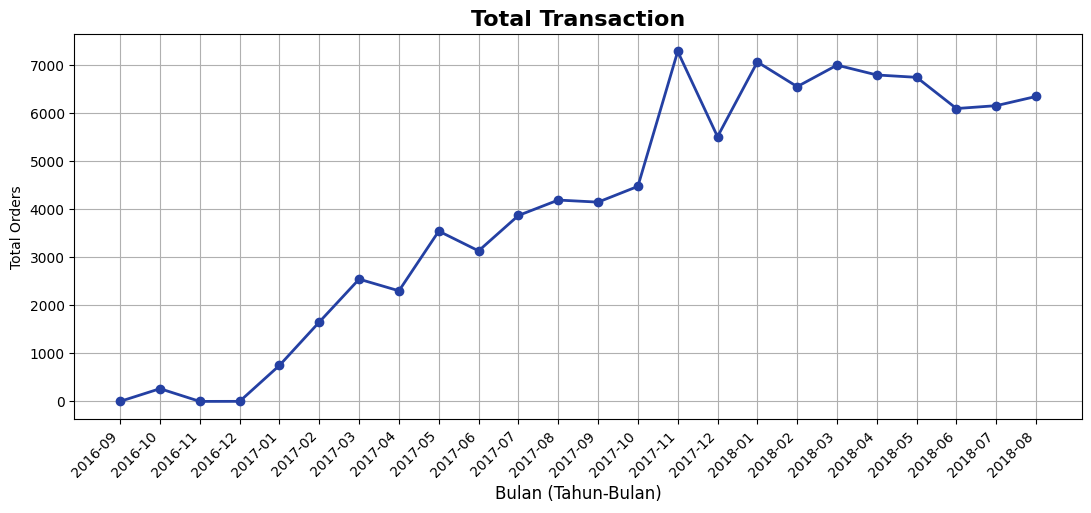

In [98]:
# visualisasi tren jumlah transaksi per bulan
plt.figure(figsize=(13, 5))
plt.plot(orders_monthly_df["order_purchase_timestamp"], orders_monthly_df["total_orders"], marker="o", linewidth=2, color="#2440a3")
plt.title("Total Transaction", fontsize=16, fontweight="bold", loc="center")
plt.xticks(fontsize=10)
plt.xticks(rotation=45, ha="right")
plt.yticks(fontsize=10)
plt.xlabel("Bulan (Tahun-Bulan)", fontsize=12)
plt.ylabel("Total Orders")
plt.grid(True)
plt.show()

**Insight :**

**Jumlah transaksi naik signifikan sepanjang 2017**, dari sekitar 760 order (Januari) menjadi sekitar 4.500 (Oktober). **Puncaknya sekitar 7.300 order pada November 2017 (kemungkinan karena lonjakan belanja akhir tahun)**. **Desember 2017 turun** ke sekitar 5.500 order, **lalu kembali** ke sekitar 7.000 **pada Januari 2018. Sepanjang 2018, jumlah order bergerak di kisaran 6.100 sampai 7.070.**


### Pertanyaan 2: Bagaimanakah Gross Merchandise Value (GMV) atau pendapatan kotor selama periode waktu yang ada?

In [99]:
gmv_monthly = all_df.resample(rule="ME", on="order_purchase_timestamp").agg(
    gmv=("price", "sum"),
    total_orders=("order_id", "nunique")
)
gmv_monthly.index = gmv_monthly.index.strftime("%Y-%m")
gmv_monthly = gmv_monthly.reset_index()
gmv_monthly

,order_purchase_timestamp,gmv,total_orders
0,2016-09,134.97,1
1,2016-10,40325.11,265
2,2016-11,0.00,0
3,2016-12,10.90,1
4,2017-01,111798.36,750
5,2017-02,234223.40,1653
6,2017-03,359198.85,2546
7,2017-04,340669.68,2303
8,2017-05,489338.25,3546
9,2017-06,421923.37,3135


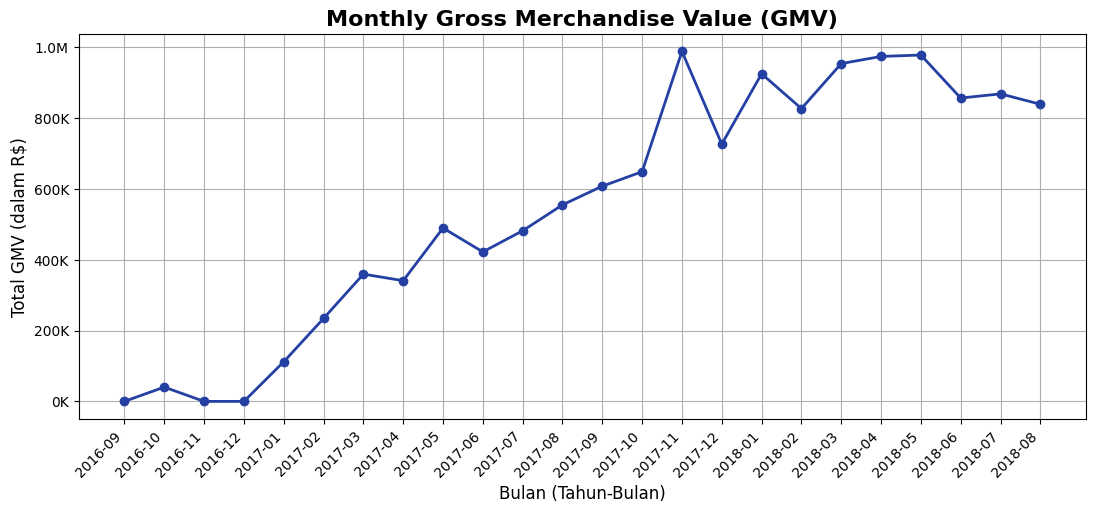

In [100]:
# visualisasi plot GMV
plt.figure(figsize=(13,5))
plt.plot(gmv_monthly["order_purchase_timestamp"], gmv_monthly["gmv"], marker="o", linewidth=2, color="#2440a3")
plt.title("Monthly Gross Merchandise Value (GMV)", fontsize=16, fontweight="bold", loc="center")
plt.xlabel("Bulan (Tahun-Bulan)", fontsize=12)
plt.xticks(fontsize=10)
# Memutar label sumbu x agar mudah dibaca
plt.xticks(rotation=45, ha="right")
plt.ylabel("Total GMV (dalam R$)", fontsize=12)
plt.yticks(fontsize=10)
# Format nominal uang pada sumbu Y kiri
formatter = ticker.FuncFormatter(lambda x, pos: f'{x*1e-3:,.0f}K' if x < 1e6 else f'{x*1e-6:,.1f}M')
plt.gca().yaxis.set_major_formatter(formatter)
plt.grid(True)
plt.show()

In [101]:
# pertumbuhan dari bulan ke bulan
orders_monthly_df["monthly_change_%"] = orders_monthly_df["total_orders"].pct_change() * 100
orders_monthly_df.round(2)

,order_purchase_timestamp,total_orders,monthly_change_%
0,2016-09,1,NaN
1,2016-10,265,26400.00
2,2016-11,0,-100.00
3,2016-12,1,inf
4,2017-01,750,74900.00
5,2017-02,1653,120.40
6,2017-03,2546,54.02
7,2017-04,2303,-9.54
8,2017-05,3546,53.97
9,2017-06,3135,-11.59


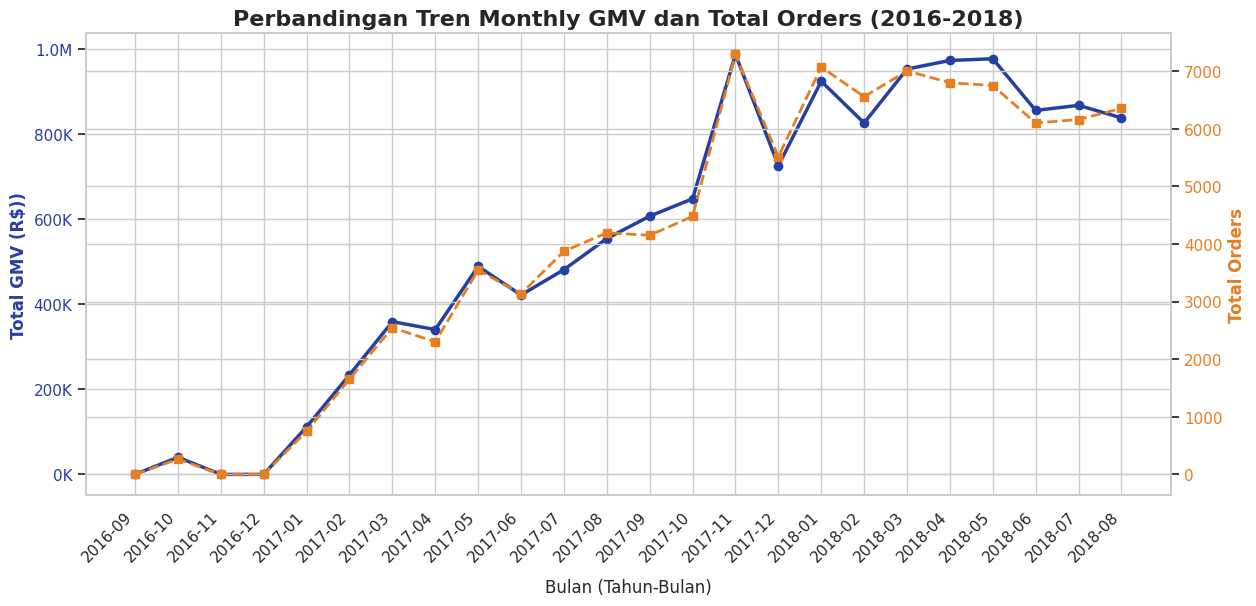

In [102]:
# visualisasi plot GMV vs Total Transaksi
sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(14, 6))
# Grafik 1: Tren GMV (Sumbu Y Sebelah Kiri)
color = '#2440a3'
ax1.set_xlabel('Bulan (Tahun-Bulan)', fontsize=12, labelpad=10)
ax1.set_ylabel('Total GMV (R$))', color=color, fontsize=12, fontweight='bold')
line1 = ax1.plot(
    gmv_monthly['order_purchase_timestamp'],
    gmv_monthly['gmv'],
    marker='o',
    linewidth=2.5,
    color=color,
    label='GMV'
)
ax1.tick_params(axis='y', labelcolor=color)
# Format nominal uang pada sumbu Y kiri
formatter_gmv = ticker.FuncFormatter(lambda x, pos: f'{x*1e-3:,.0f}K' if x < 1e6 else f'{x*1e-6:,.1f}M')
ax1.yaxis.set_major_formatter(formatter_gmv)

# Grafik 2 : Total Order
# Membuat sumbu Y kedua (Sumbu Y Sebelah Kanan) untuk Total Orders
ax2 = ax1.twinx()
color2 = '#E67E22'
ax2.set_ylabel('Total Orders', color=color2, fontsize=12, fontweight='bold')
line2 = ax2.plot(
    gmv_monthly['order_purchase_timestamp'],
    gmv_monthly['total_orders'],
    marker='s',
    linewidth=2.0,
    linestyle='--',
    color=color2,
    label='Total Orders'
)
ax2.tick_params(axis='y', labelcolor=color2)

# Memutar label sumbu x
ax1.tick_params(axis="x", rotation=45)
plt.setp(ax1.get_xticklabels(), ha="right")

plt.title("Perbandingan Tren Monthly GMV dan Total Orders (2016-2018)", fontsize=16, fontweight='bold', loc="center")
plt.show()

**Insight :**

* **GMV naik sepanjang tahun 2017 dan mencapai puncak pada bulan November 2017** dengan nilai sekitar 1juta R$, **lalu turun** pada kisaran 700ribu pada bulan Desember, **kemudian mengalami kenaikan kembali pada 2018** dan nilainya bertahan pada kisaran 800-900 ribu.
*   P**ola transaksi dan GMV hampir identik. Keduanya naik, memuncak, dan turun pada bulan yang sama** (puncak November 2017, turun Desember 2017, pulih Januari 2018). **Artinya pertumbuhan GMV utamanya didorong oleh jumlah transaksi.**

### Pertanyaan 3: Kategori produk mana yang paling banyak/sedikit terjual dan memiliki GMV tertinggi/terendah?

In [103]:
category_df = all_df.groupby("product_category_eng").agg(
    total_items=("order_item_id", "count"),
    total_orders=("order_id", "nunique"),
    gmv=("price", "sum")
).sort_values("total_items", ascending=False).reset_index()
category_df.head()

,product_category_eng,total_items,total_orders,gmv
0,bed_bath_table,10953,9272,1023434.76
1,health_beauty,9465,8647,1233131.72
2,sports_leisure,8431,7530,954852.55
3,furniture_decor,8160,6307,711927.69
4,computers_accessories,7644,6530,888724.61


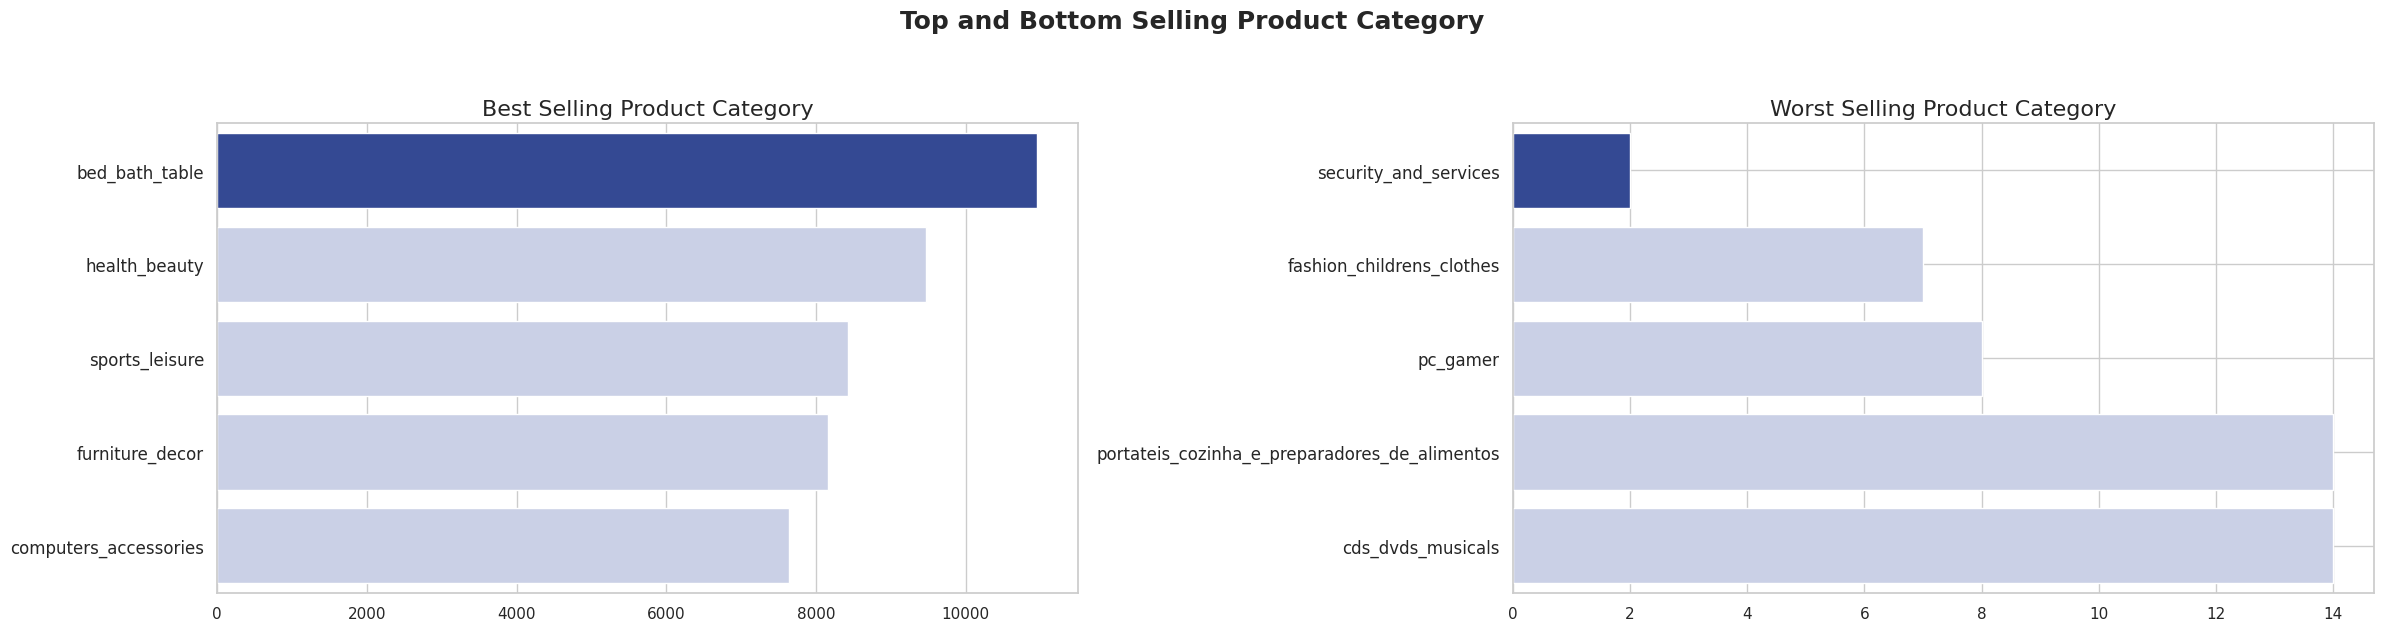

In [104]:
# visualisasi jumlah terjual (tertinggi dan terendah)
top_selling = category_df.sort_values("total_items", ascending=False).head()
bottom_selling = category_df.sort_values("total_items", ascending=True).head()

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(24, 6))
colors = ["#2440a3", "#c5cdeb", "#c5cdeb", "#c5cdeb", "#c5cdeb"]

sns.barplot(data=top_selling, x="total_items", y="product_category_eng", hue="product_category_eng", palette=colors, legend=False, ax=ax[0])
ax[0].set_ylabel(None)
ax[0].set_xlabel(None)
ax[0].set_title("Best Selling Product Category", loc="center", fontsize=16)
ax[0].tick_params(axis='y', labelsize=12)

sns.barplot(data=bottom_selling, x="total_items", y="product_category_eng", hue="product_category_eng", palette=colors, legend=False, ax=ax[1])
ax[1].set_ylabel(None)
ax[1].set_xlabel(None)
ax[1].set_title("Worst Selling Product Category", loc="center", fontsize=16)
ax[1].tick_params(axis='y', labelsize=12)

plt.suptitle("Top and Bottom Selling Product Category", fontsize=18, fontweight="bold", y=1.05)
plt.grid(True)
plt.tight_layout()
plt.show()

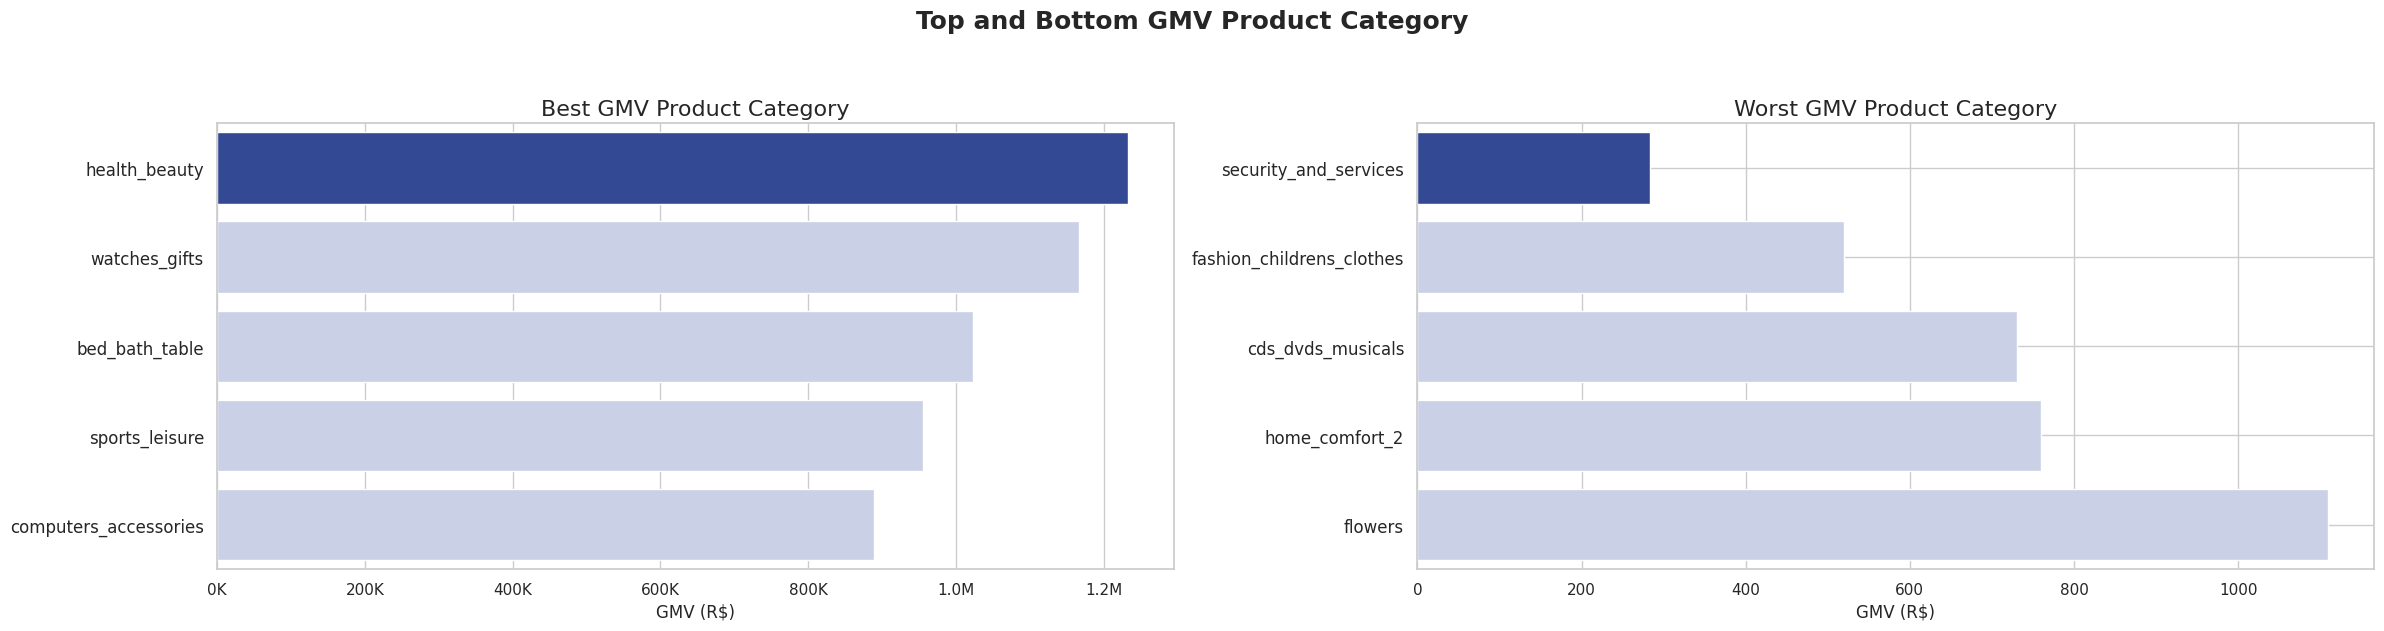

In [105]:
# visualisasi produk dengan gmv tertinggi dan terendah
top_gmv = category_df.sort_values("gmv", ascending=False).head()
worst_gmv = category_df.sort_values("gmv", ascending=True).head()

formatter_gmv = ticker.FuncFormatter(lambda x, pos: f'{x*1e-3:,.0f}K' if x < 1e6 else f'{x*1e-6:,.1f}M')

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(24, 6))
colors = ["#2440a3", "#c5cdeb", "#c5cdeb", "#c5cdeb", "#c5cdeb"]

sns.barplot(data=top_gmv, x="gmv", y="product_category_eng", hue="product_category_eng", palette=colors, legend=False, ax=ax[0])
ax[0].set_ylabel(None)
ax[0].set_xlabel("GMV (R$)")
ax[0].xaxis.set_major_formatter(formatter_gmv)
ax[0].set_title("Best GMV Product Category", loc="center", fontsize=16)
ax[0].tick_params(axis='y', labelsize=12)

sns.barplot(data=worst_gmv, x="gmv", y="product_category_eng", hue="product_category_eng", palette=colors, legend=False, ax=ax[1])
ax[1].set_ylabel(None)
ax[1].set_xlabel("GMV (R$)")
ax[0].xaxis.set_major_formatter(formatter_gmv)
ax[1].set_title("Worst GMV Product Category", loc="center", fontsize=16)
ax[1].tick_params(axis='y', labelsize=12)

plt.suptitle("Top and Bottom GMV Product Category", fontsize=18, fontweight="bold", y=1.05)
plt.grid(True)
plt.tight_layout()
plt.show()

**Insight :**

*  Kategori paling banyak terjual: **bed_bath_table**(10953) diikuti **health_beauty** (9465), **sport_leisure** (8431) dan paling sedikit: **security_and_services** (2) diikuti **fashion_children_clothes** (7), dan **pc_gamer** (8)
*  Kategori produk GMV tertinggi: **health_beauty**, diikuti dengan **watches_gift** dan **bed_bath_table**. Terendah: **security_and_services** diikuti **fashion_children_clothes** dan **cds_dvds_musicals**.

### Pertanyaan 4 : Bagaimana pesebaran customer dan seller berdasarkan wilayah, dan wilayah mana yang paling terkonsentrasi?

In [106]:
# Demografi customer berdasarkan state
cust_state = all_df.groupby(by="customer_state").agg(
    total_customers=("customer_unique_id", "nunique"),
    total_orders=("order_id", "nunique"),
).reset_index()

In [107]:
# Demografi seller berdasarkan state
sellr_state = all_df.groupby(by="seller_state").agg(
    total_sellers=("seller_id", "nunique")
).reset_index()


In [108]:
map1_df = (
    brazil_states
    .merge(cust_state, how="left", left_on="abbrev_state", right_on="customer_state")
    .merge(sellr_state, how="left", left_on="abbrev_state", right_on="seller_state")
)
cols = ["total_customers", "total_sellers"]
map1_df[cols] = map1_df[cols].fillna(0)

# rasio customer per seller
map1_df["customer_per_seller"] = (
    map1_df["total_customers"] / map1_df["total_sellers"].replace(0, np.nan)
).round(1)

map1_df.head()

,code_state,name_state,abbrev_state,code_region,name_region,year,geometry,customer_state,total_customers,total_orders,seller_state,total_sellers,customer_per_seller
0,11.0,Rondônia,RO,1.0,Norte,2020.0,"POLYGON ((-65.3815 -10.42907, -65.37916 -10.41...",RO,231,243,RO,2.0,115.5
1,12.0,Acre,AC,1.0,Norte,2020.0,"POLYGON ((-71.07772 -9.82774, -71.08554 -9.839...",AC,76,80,NaN,0.0,NaN
2,13.0,Amazonas,AM,1.0,Norte,2020.0,"POLYGON ((-69.89403 -4.00068, -69.7123 -3.0006...",AM,140,145,AM,1.0,140.0
3,14.0,Roraima,RR,1.0,Norte,2020.0,"POLYGON ((-63.95934 2.46763, -63.96041 2.47416...",RR,40,41,NaN,0.0,NaN
4,15.0,Pará,PA,1.0,Norte,2020.0,"MULTIPOLYGON (((-51.42367 -0.43661, -51.42073 ...",PA,922,946,PA,1.0,922.0


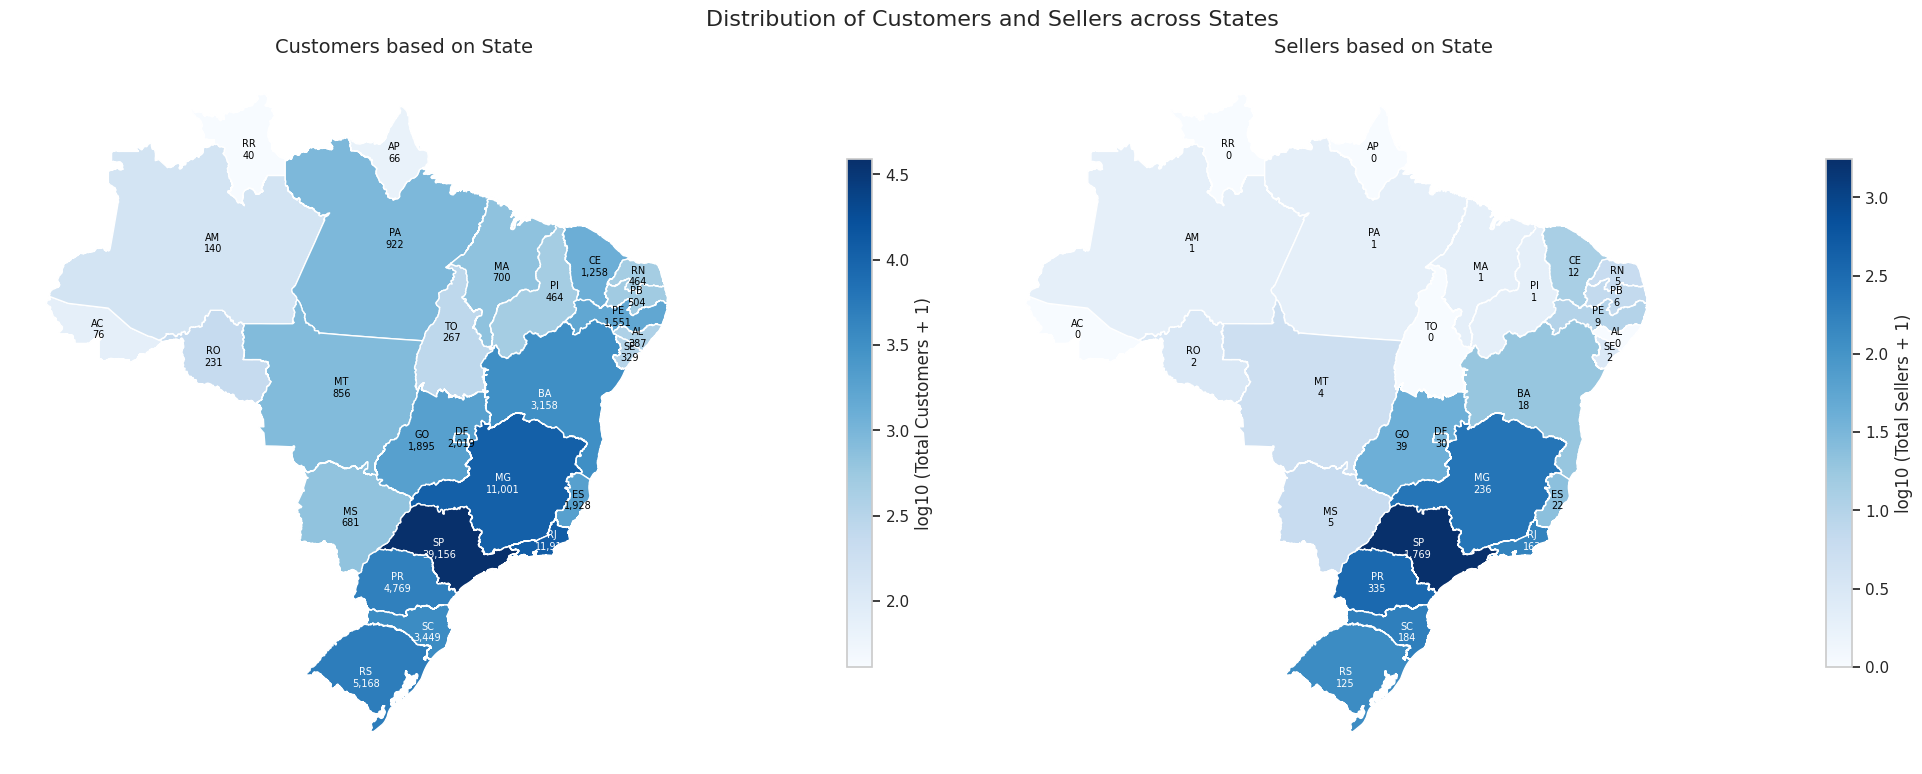

In [109]:
# visualisasi pesebaran customer dan seller
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 8))

config = [
    (ax[0], "total_customers", "Blues", "Total Customers", "Customers based on State",
     lambda v: f"{v:,.0f}"),
    (ax[1], "total_sellers", "Blues", "Total Sellers", "Sellers based on State",
     lambda v: f"{v:,.0f}")
]

for a, column, cmap, label, title, formatter in config:
    # transformasi logaritmik untuk melihat perbedaan antar-state
    log_values = np.log10(map1_df[column] + 1)
    map1_df.plot(
        column=log_values,
        cmap=cmap,
        edgecolor="white",
        linewidth=1,
        ax=a,
        legend=True,
        legend_kwds={"label": f"log10 ({label} + 1)", "shrink": 0.7}
    )

    # normalisasi warna label
    norm = mcolors.Normalize(vmin=log_values.min(), vmax=log_values.max())

    # label state dan nilai
    for idx, row in map1_df.iterrows():
        p = row.geometry.representative_point()
        text_color = "white" if norm(log_values[idx]) > 0.6 else "black"
        a.text(p.x, p.y, f"{row['abbrev_state']}\n{formatter(row[column])}",
               ha="center", va="center", fontsize=7, color=text_color)

    a.set_title(title, fontsize=14)
    a.axis("off")

plt.suptitle("Distribution of Customers and Sellers across States", fontsize=16)
plt.tight_layout()
plt.show()

In [110]:
# wilayah dengan jumlah transaksi tertinggi dan terendah
region_df = all_df.groupby(by="customer_state").agg(
    total_orders=("order_id", "nunique"),
    gmv=("price", "sum")
).reset_index()
region_df

,customer_state,total_orders,gmv
0,AC,80,15930.97
1,AL,397,78855.72
2,AM,145,22155.84
3,AP,67,13374.81
4,BA,3256,493584.14
5,CE,1279,219757.38
6,DF,2080,296498.41
7,ES,1995,268643.45
8,GO,1957,282836.70
9,MA,717,117009.38


In [111]:
map_df = (
    brazil_states.merge (
        region_df,
        how="left",
        left_on="abbrev_state",
        right_on="customer_state",
    )
)
cols = ["total_orders", "gmv"]
map_df[cols] = map_df[cols].fillna(0)
map_df.head()

,code_state,name_state,abbrev_state,code_region,name_region,year,geometry,customer_state,total_orders,gmv
0,11.0,Rondônia,RO,1.0,Norte,2020.0,"POLYGON ((-65.3815 -10.42907, -65.37916 -10.41...",RO,243,45682.76
1,12.0,Acre,AC,1.0,Norte,2020.0,"POLYGON ((-71.07772 -9.82774, -71.08554 -9.839...",AC,80,15930.97
2,13.0,Amazonas,AM,1.0,Norte,2020.0,"POLYGON ((-69.89403 -4.00068, -69.7123 -3.0006...",AM,145,22155.84
3,14.0,Roraima,RR,1.0,Norte,2020.0,"POLYGON ((-63.95934 2.46763, -63.96041 2.47416...",RR,41,7057.47
4,15.0,Pará,PA,1.0,Norte,2020.0,"MULTIPOLYGON (((-51.42367 -0.43661, -51.42073 ...",PA,946,174470.59


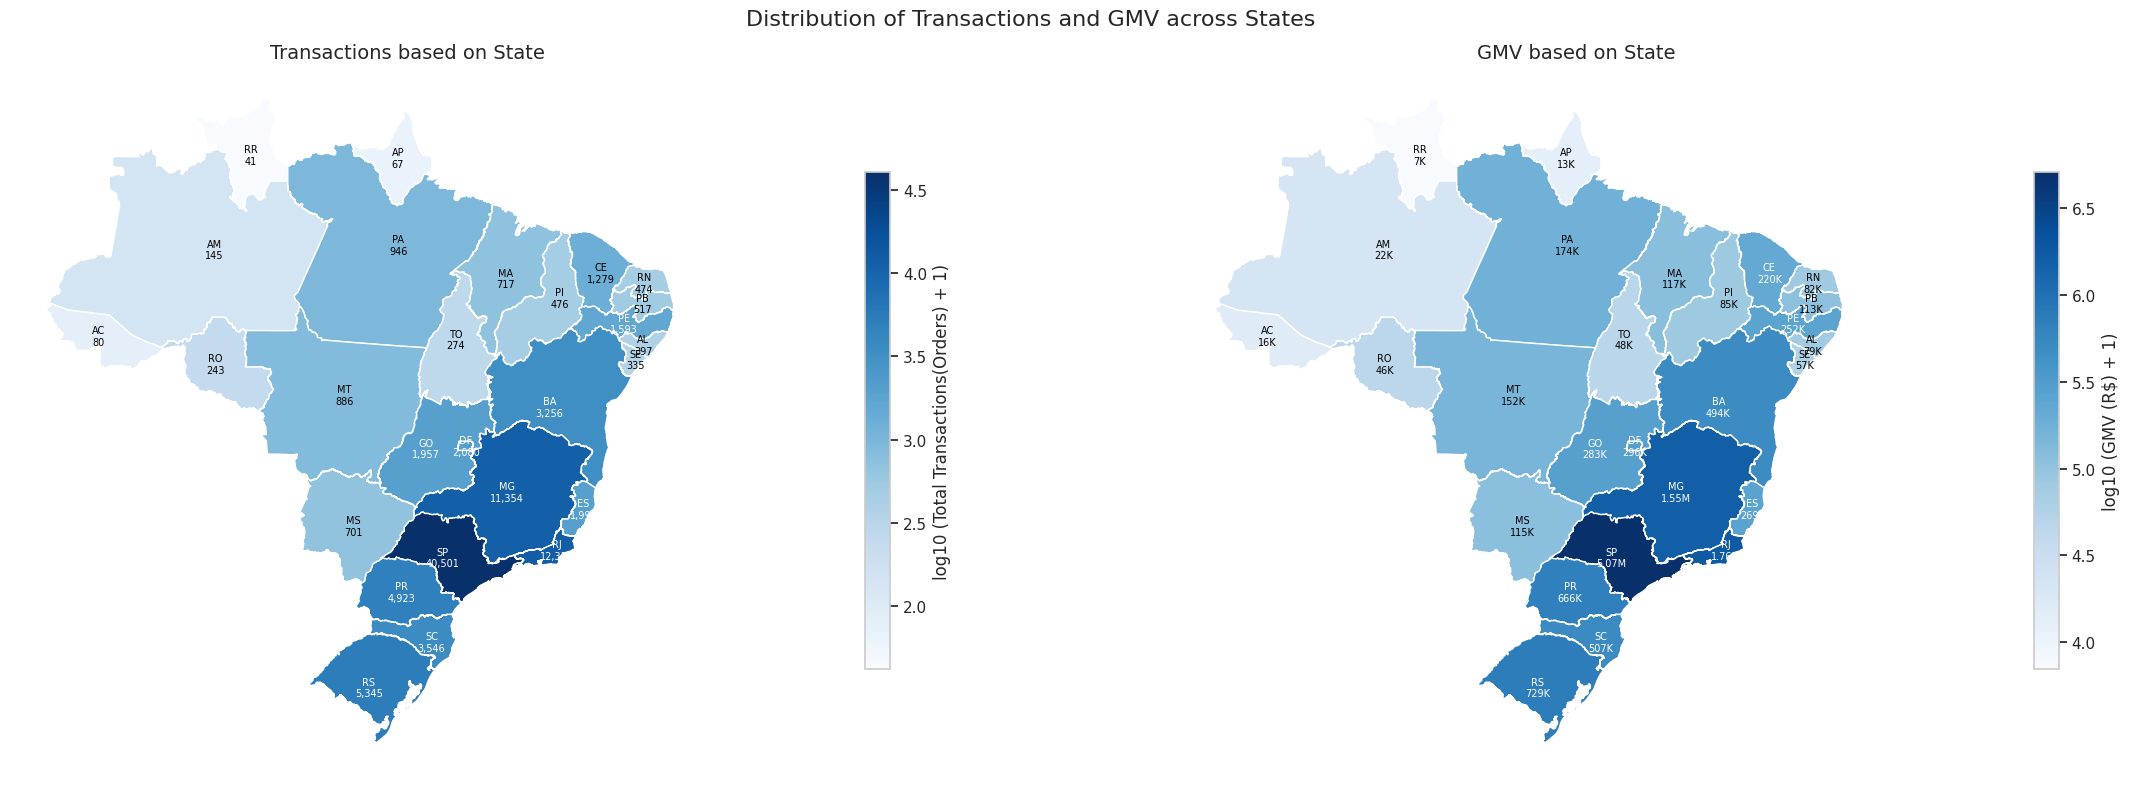

In [112]:
# visualisasi pesebaran transaksi dan gmv pada peta
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(24,8))

config = [
    (ax[0], "total_orders", "Blues", "Total Transactions(Orders)", "Transactions based on State", lambda v: f"{v:,.0f}"),
    (ax[1], "gmv", "Blues", "GMV (R$)", "GMV based on State", lambda v: f"{v/1e6:,.2f}M" if v >= 1e6 else f"{v/1e3:,.0f}K")
]

for a, column, cmap, label, title, formatter in config:
  # transformasi logaritmik untuk melihat perbedaan antar-state
  log_values = np.log10(map_df[column]+1)
  map_df.plot(
      column=log_values,
      cmap=cmap,
      edgecolor="white",
      linewidth=1,
      ax=a,
      legend=True,
      legend_kwds={"label": f"log10 ({label} + 1)", "shrink": 0.7}
  )
  # normalisasi warna label
  norm = mcolors.Normalize(vmin=log_values.min(), vmax=log_values.max())
  # label state dan nilai
  for idx, row in map_df.iterrows():
    p = row.geometry.representative_point()
    text_color = "white" if norm(log_values[idx])> 0.5 else "black"
    a.text(p.x, p.y, f"{row['abbrev_state']}\n{formatter(row[column])}", ha="center", va="center", fontsize=7, color=text_color)

  a.set_title(title, fontsize=14)
  a.set_ylabel(None)
  a.set_xlabel(None)
  a.axis("off")

plt.suptitle("Distribution of Transactions and GMV across States", fontsize=16)
plt.tight_layout()
plt.show()

**Insight :**
*  Customer **terkonsentrasi di daerah Tenggara**. **SP** memiliki sekitar 39 ribu customer (*sekitar 42% dari total*), diikuti SP, RJ, serta MG.
*   Seller sangat terpusat, dimana **SP** memiliki sekitar 1.769 seller (*sekitar 60% dari total*), disusul PR, MG, dan SC.
*   **Ada ketimpangan antara customer dan seller**, seperti pada PA (922 customer, 1 seller), MA (700, 1), PI (464, 1), dan RO (231, 2) punya banyak customer tapi sangat sedikit seller. **AC, RR, AP, TO, dan AL punya customer tetapi tidak punya seller sama sekali.**
* **Transaksi dan GMV tertinggi di yakni SP, RJ, MG dan terendah di RR, AP, AC.**

## Analisis RFM

In [113]:
rfm_df = all_df.groupby(by="customer_unique_id", as_index=False).agg({
    "order_purchase_timestamp":"max", # mengambil data order terakhir
    "order_id":"nunique", # menghitung jumlah order
    "price":"sum" # menghitung jumlah gmv yang dihasilkan
})

rfm_df.columns =["customer_unique_id", "last_purchase", "frequency", "monetary"]

# tanggal acuan = sehari setelah transaksi terakhir di all_df
recent_date = all_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
rfm_df["recency"] = (recent_date - rfm_df["last_purchase"]).dt.days

rfm_df.drop("last_purchase", axis=1, inplace=True)
rfm_df.head()

,customer_unique_id,frequency,monetary,recency
0,0000366f3b9a7992bf8c76cfdf3221e2,1,129.90,112
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.90,115
2,0000f46a3911fa3c0805444483337064,1,69.00,537
3,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,321
4,0004aac84e0df4da2b147fca70cf8255,1,180.00,288


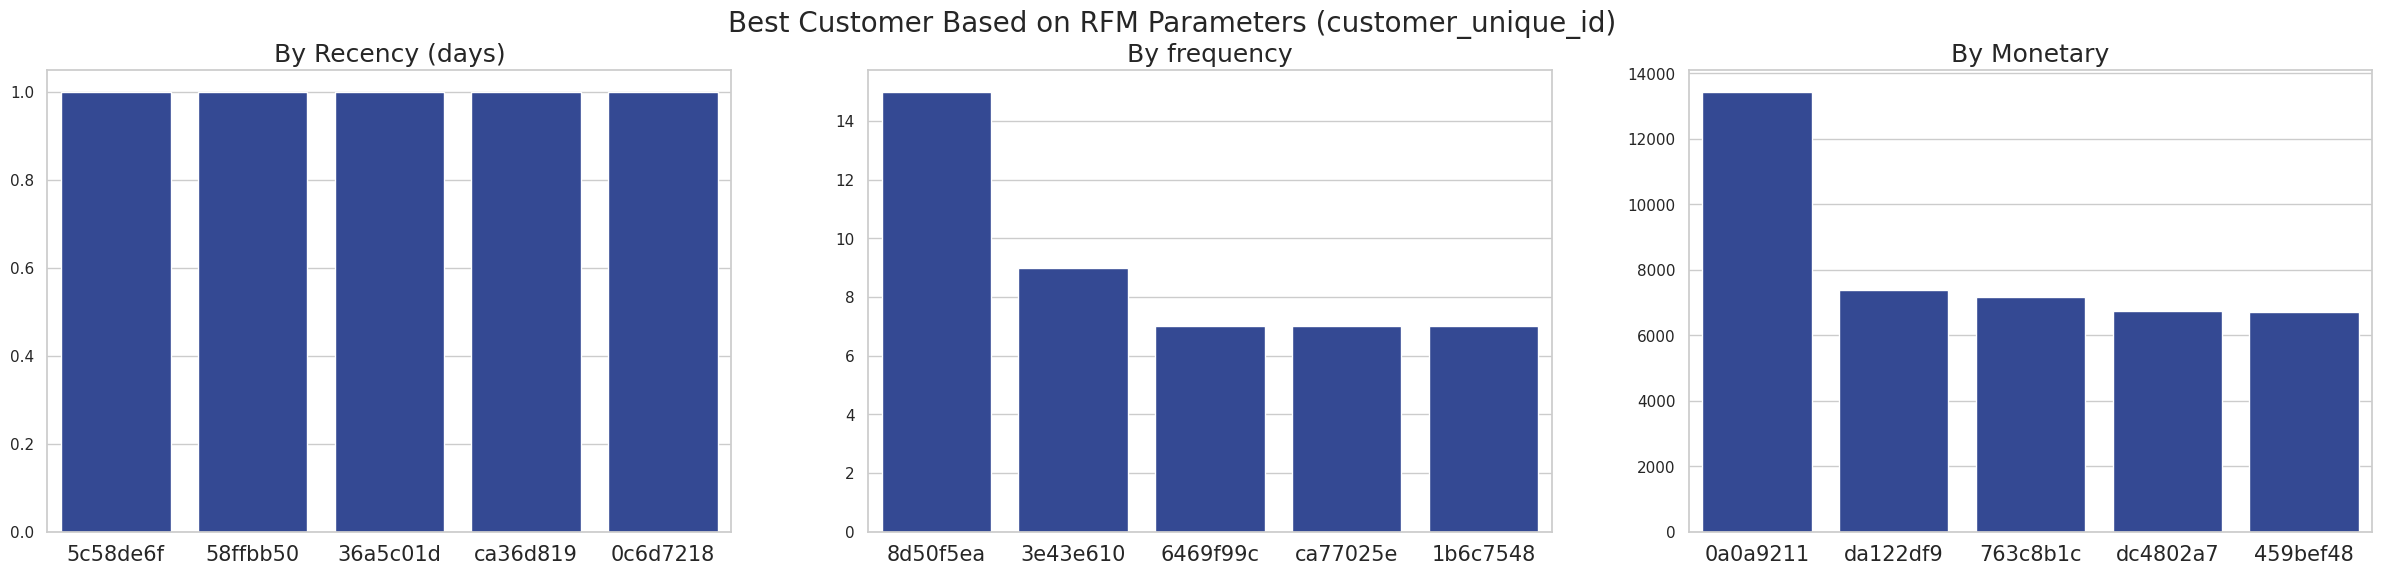

In [114]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(30, 6))

colors = ["#2440a3", "#2440a3", "#2440a3", "#2440a3", "#2440a3"]

recency_data = rfm_df.sort_values(by="recency", ascending=True).head(5).copy()
recency_data["cust_id_short"] = recency_data["customer_unique_id"].str[:8]

sns.barplot(y="recency", x="cust_id_short", data=recency_data, hue="customer_unique_id", legend=False, palette=colors, ax=ax[0])
ax[0].set_ylabel(None)
ax[0].set_xlabel(None)
ax[0].set_title("By Recency (days)", loc="center", fontsize=18)
ax[0].tick_params(axis='x', labelsize=15)

frequency_data = rfm_df.sort_values(by="frequency", ascending=False).head(5).copy()
frequency_data["cust_id_short"] = frequency_data["customer_unique_id"].str[:8]

sns.barplot(y="frequency", x="cust_id_short", data=frequency_data, hue="customer_unique_id", legend=False, palette=colors, ax=ax[1])
ax[1].set_ylabel(None)
ax[1].set_xlabel(None)
ax[1].set_title("By frequency", loc="center", fontsize=18)
ax[1].tick_params(axis='x', labelsize=15)

monetary_data = rfm_df.sort_values(by="monetary", ascending=False).head(5).copy()
monetary_data["cust_id_short"] = monetary_data["customer_unique_id"].str[:8]

sns.barplot(y="monetary", x="cust_id_short", data=monetary_data, hue="customer_unique_id", legend=False, palette=colors, ax=ax[2])
ax[2].set_ylabel(None)
ax[2].set_xlabel(None)
ax[2].set_title("By Monetary", loc="center", fontsize=18)
ax[2].tick_params(axis='x', labelsize=15)

plt.suptitle("Best Customer Based on RFM Parameters (customer_unique_id)", fontsize=20)
plt.show()

#### Mengurutkan customer berdasarkan recency, frequency, & monetary score

Melakukan scoring RFM dengan metode :
*   Recency dan Monetary dilakukan metode kuartil (qcut), dimana semua customer diurutkan lalu dibagi menjadi 5 kelompok berukuran sama, masing-masing sekitar 20%.
*   Sedangkan pada Frequency, karena banyak data yang bernilai 1, maka ambang dilakukan secara manual yakni dari 1 s.d. 5 untuk frequency dengan nilai 5 atau lebih.



In [115]:
# Recency: makin kecil makin bagus
rfm_df["R_score"] = pd.qcut(rfm_df["recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)

# Monetary: makin besar makin bagus
rfm_df["M_score"] = pd.qcut(rfm_df["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Frequency: batas manual karena banyak data 1 order
rfm_df["F_score"] = pd.cut(
    rfm_df["frequency"], bins=[0, 1, 2, 3, 4, np.inf], labels=[1, 2, 3, 4, 5]
).astype(int)

rfm_df["RFM_score"] = rfm_df["R_score"].astype(str) + rfm_df["F_score"].astype(str) + rfm_df["M_score"].astype(str)
rfm_df.head()

,customer_unique_id,frequency,monetary,recency,R_score,M_score,F_score,RFM_score
0,0000366f3b9a7992bf8c76cfdf3221e2,1,129.90,112,4,4,1,414
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.90,115,4,1,1,411
2,0000f46a3911fa3c0805444483337064,1,69.00,537,1,2,1,112
3,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,321,2,1,1,211
4,0004aac84e0df4da2b147fca70cf8255,1,180.00,288,2,5,1,215


In [122]:
def segmentasi(row):
    r, f, m = row["R_score"], row["F_score"], row["M_score"]
    if r >= 4 and m >= 4:
        return "Top Customers"
    elif f >= 2:
        return "Repeat Customers"
    elif r >= 4:
        return "Recent / New Customers"
    elif r <= 2 and m >= 4:
        return "Big Spenders at Risk"
    elif r <= 2 and m <= 2:
        return "Lost Customers"
    else:
        return "Need Attention"

rfm_df["segment"] = rfm_df.apply(segmentasi, axis=1)

segment_df = (rfm_df.groupby("segment").agg(
        total_customers=("customer_unique_id", "nunique"),
        avg_recency=("recency", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean")
    ).round(1).sort_values("total_customers", ascending=False).reset_index()
)
segment_df["persen_%"] = (segment_df["total_customers"] / segment_df["total_customers"].sum() * 100).round(1)
segment_df

,segment,total_customers,avg_recency,avg_frequency,avg_monetary,persen_%
0,Need Attention,25398,269.9,1.0,118.0,27.2
1,Recent / New Customers,21657,89.6,1.0,55.5,23.2
2,Top Customers,15414,91.5,1.1,270.7,16.5
3,Lost Customers,15236,396.1,1.0,40.0,16.3
4,Big Spenders at Risk,13788,394.6,1.0,276.8,14.8
5,Repeat Customers,1865,286.1,2.1,226.5,2.0


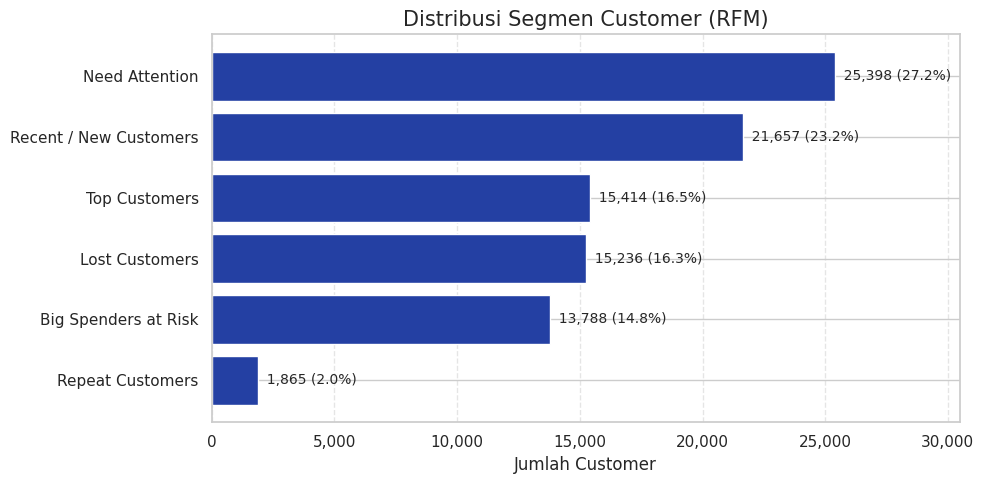

In [123]:
fig, ax = plt.subplots(figsize=(10, 5))

data = segment_df.sort_values("total_customers")
bars = ax.barh(data["segment"], data["total_customers"], color="#2440a3")

for bar, persen in zip(bars, data["persen_%"]):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2,
            f"  {bar.get_width():,.0f} ({persen}%)", va="center", fontsize=10)

ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x:,.0f}"))
ax.set_xlim(0, data["total_customers"].max() * 1.2)
ax.set_title("Distribusi Segmen Customer (RFM)", fontsize=15)
ax.set_xlabel("Jumlah Customer")
ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [118]:
all_df.to_csv("all_data.csv", index=False)

## Conclusion & Recommendation

 **Conclusion pertanyaan 1:**


*   Jumlah transaksi naik signifikan sepanjang 2017, uncaknya pada November 2017 (kemungkinan karena lonjakan belanja akhir tahun). Namun, mengalami penuruanan pada Desember 2017 lalu perlahan naik pada Januari 2018.

 **Conclusion pertanyaan 2:**

* GMV naik sepanjang tahun 2017 dan mencapai puncak pada bulan November 2017 lalu turun pada bulan Desember, kemudian perlahan mengalami kenaikan kembali pada 2018
*  Pola transaksi dan GMV hampir identik. Artinya pertumbuhan GMV utamanya didorong oleh jumlah transaksi.

 **Conclusion pertanyaan 3:**

*  Kategori paling banyak terjual: **bed_bath_table** diikuti **health_beauty**, **sport_leisure** dan paling sedikit: **security_and_services** diikuti **fashion_children_clothes**, dan **pc_gamer**
*  Kategori produk GMV tertinggi: **health_beauty**, diikuti dengan **watches_gift** dan **bed_bath_table**. Terendah: **security_and_services** diikuti **fashion_children_clothes** dan **cds_dvds_musicals**.
*  Peringkat jumlah terjual dan peringkat GMV berbeda. **Kategori yang banyak terjual tapi GMV-nya lebih rendah berarti harga per item lebih murah, sedangkan yang GMV-nya tinggi dengan item lebih sedikit berarti harga per item lebih mahal**.

 **Conclusion pertanyaan 4:**

*  Customer terkonsentrasi di daerah Tenggara. SP memiliki sekitar 42% dari total, diikuti SP, RJ, serta MG.
*   Seller sangat terpusat, dimana SP memiliki sekitar 60% dari total, disusul PR, MG, dan SC.
*   Ada ketimpangan antara customer dan seller, seperti pada PA, MA, PI, dan RO punya banyak customer tapi sangat sedikit seller. AC, RR, AP, TO, dan AL punya customer tetapi tidak punya seller sama sekali.
* Transaksi dan GMV tertinggi sejalan dengan jumlah customer yang paling banyak juga pada wilayah tersebut.





**Rekomendasi Action Item:**

* Melakukan fokus pada pertumbuhan jumlah transaksi, dapat melalui akuisisi customer baru dan program *repeat order* (misalnya voucher untuk pembelian berikutnya dan voucher untuk customer yang baru pertama kali belanja).
* Dapat memberikan gratis ongkir dengan minimum belanja, promo *bundling*, atau rekomendasi produk pelengkap untuk meningkatkan jumlah order.
* Melakukan persiapan lonjakan akhir tahun dengan seller dan mitra logistik, dan melakukan rancangan kampanye lanjutan pada bulan setelahnya (Desember sampai Januari) agar penurunan setelah puncak tidak sebesar 2017.
* Untuk kategori produk dengan GMV tertinggi, produk dapat dijadikan pada etalase promo utama, sedangkan untuk kategori pembelian item tinggi tapi nilai pendapatan lebih rendah, dorong *upsell* atau *bundling* agar nilai per order naik.
* Dapat melakukan *onboarding* seller terarah pada state dengan customer banyak tapi seller sedikit (PA, MA, PI, BA), misalnya lewat keringanan komisi untuk seller baru di sana.
* Dapat dicatat sebagai risiko bahwa sekitar 60% seller berada di satu state (SP), karena gangguan di SP dapat berdampak besar pada platform.
* Melakukan analisis lebih lanjut terkait hambatan logistik pada state dengan sedikit customer.


